# Estimating chess game length

## Question
Can the number of turns explain the duration of a chess game using linear regression?

> **Important limitation:** `turns` is known only after a game ends, so this is an explanatory model of the relationship between turns and duration—not a model that can predict duration before a game starts.


In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split


## 1. Load and clean the data

Game duration is calculated from the difference between `created_at` and `last_move_at`. The filters below keep positive, short games with a 10-minute base time and fewer than 300 turns (to remove outliers). These choices define the population being analyzed and should not be interpreted as universal chess rules.


In [50]:
data = pd.read_csv('../Resources/games_data.csv', index_col=0)

for column in ['created_at', 'last_move_at']:
    data[column] = pd.to_datetime(data[column], unit='ms', utc=True)

data['game_length'] = data['last_move_at'] - data['created_at']
data['game_length_minutes'] = data['game_length'].dt.total_seconds() / 60

raw_rows = len(data)
filtered = data.loc[
    data['game_length'].gt(pd.Timedelta(0))
    & data['game_length'].lt(pd.Timedelta(minutes=60))
    & data['increment_code'].fillna('').str.startswith('10')
    & data['turns'].lt(300)
    & data['turns'].gt(5)
].copy()

data = filtered
print(f'Rows before filtering: {raw_rows:,}')
print(f'Rows after filtering:  {len(data):,}')
print(f'Rows removed:          {raw_rows - len(data):,}')
print('Missing values:', data[['game_length_minutes', 'turns']].isna().sum().to_dict())


Rows before filtering: 20,058
Rows after filtering:  5,072
Rows removed:          14,986
Missing values: {'game_length_minutes': 0, 'turns': 0}


## 2. Explore the relationship

With our clean data, we can now explore the relationship between the number of turns and the duration of a chess game. The response variable is game duration in minutes. The predictor is the number of turns. We can use a hexbin plot to make dense regions easier to see rather than a scatter plot alone. 


       game_length_minutes    turns
count              5072.00  5072.00
mean                 10.66    63.62
std                   6.33    33.17
min                   0.21     6.00
25%                   5.92    40.00
50%                   9.84    58.00
75%                  14.65    81.00
max                  57.13   226.00
Correlation: 0.622


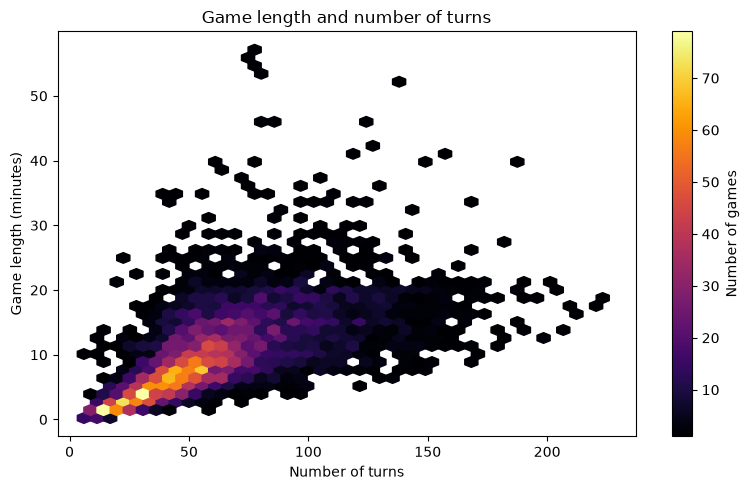

In [51]:
print(data[['game_length_minutes', 'turns']].describe().round(2))
print(f"Correlation: {data['game_length_minutes'].corr(data['turns']):.3f}")

plt.figure(figsize=(8, 5))
plt.hexbin(data['turns'], data['game_length_minutes'], gridsize=40, cmap='inferno', mincnt=1)
plt.colorbar(label='Number of games')
plt.xlabel('Number of turns')
plt.ylabel('Game length (minutes)')
plt.title('Game length and number of turns')
plt.tight_layout()
plt.show()


## 3. Train and evaluate the model

We can use a held-out test set to evaluate the model. This helps ensure that the model's performance is not just due to overfitting on the training data. We will also compare the model's performance to a simple baseline that predicts the mean duration for all games.

If linear regression does not outperform this baseline, then using `turns` is not adding useful predictive information.


In [ ]:
X = data[['turns']]
y = data['game_length_minutes']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

baseline_pred = np.full(len(y_test), y_train.mean())

def report_metrics(name, actual, predicted):
    print(f'{name}')
    print(f'  MAE:  {mean_absolute_error(actual, predicted):.2f} minutes')
    print(f'  RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.2f} minutes')
    print(f'  R²:   {r2_score(actual, predicted):.3f}')

report_metrics('Mean baseline', y_test, baseline_pred)
report_metrics('Linear regression', y_test, y_pred)
print(f'Coefficient: {model.coef_[0]:.3f} minutes per turn')
print(f'Intercept:   {model.intercept_:.3f} minutes')


Mean baseline
  MAE:  4.77 minutes
  RMSE: 5.96 minutes
  R²:   -0.003
Linear regression
  MAE:  3.47 minutes
  RMSE: 4.59 minutes
  R²:   0.404
Coefficient: 0.119 minutes per turn
Intercept:   3.135 minutes


## 4. Visualize predictions and residuals

Now that our model has been trained and evaluated, we can visualize the predictions. This helps us understand how well the model fits the data and whether there are any patterns in the errors that might suggest improvements to the model.

We can plot the predicted durations against the actual durations, as well as the residuals. The residuals are the differences between the actual and predicted durations. If the model is a good fit, we would expect the residuals to be randomly distributed around zero, with no clear patterns.


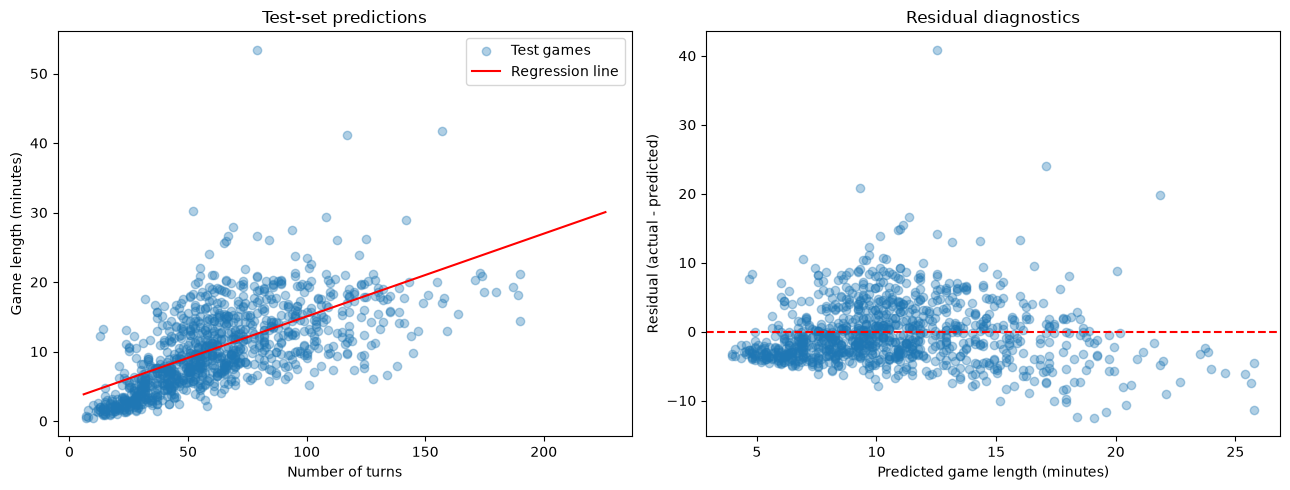

In [55]:
line_data = pd.DataFrame({'turns': np.linspace(X['turns'].min(), X['turns'].max(), 200)})
line_data['predicted_minutes'] = model.predict(line_data[['turns']])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot line of best fit and test-set predictions
axes[0].scatter(X_test['turns'], y_test, alpha=0.35, label='Test games')
axes[0].plot(line_data['turns'], line_data['predicted_minutes'], color='red', label='Regression line')
axes[0].set_xlabel('Number of turns')
axes[0].set_ylabel('Game length (minutes)')
axes[0].set_title('Test-set predictions')
axes[0].legend()

# Plot residuals
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.35)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted game length (minutes)')
axes[1].set_ylabel('Residual (actual - predicted)')
axes[1].set_title('Residual diagnostics')

plt.tight_layout()
plt.show()


## 5. Conclusion and limitations

The linear regression model quantifies the relationship between game length and turns, but it should not be used as a pre-game forecasting model because the number of turns is not known in advance. A true pre-game model should instead use only information available before play, such as player ratings, rated status, and time-control features from `increment_code`.

Further improvements could include cross-validation, separate models for different time controls, nonlinear models, and prediction intervals.
